In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import milp, LinearConstraint, Bounds

In [71]:
plt.rc('font', family='Malgun Gothic')
plt.rc('axes', unicode_minus=False)
pd.set_option('display.max_columns', None)

In [72]:
dong = pd.read_csv('dong_result.csv')
route = pd.read_csv('route_result.csv', dtype={'노선': str})
route_dong = pd.read_csv('route_dong_result.csv', dtype={'노선': str})
dong.shape, route.shape, route_dong.shape

((421, 12), (238, 11), (6548, 15))

# 최적화
- A[동, 노선]: 그 노선에 저상버스 1대를 넣으면 그 동의 접근성이 얼마나 오르는지
- gain: 노선별 1대당 해소 인원

In [73]:
route_dong['대당증가'] = route_dong['동내비중'] / route_dong['인가대수']
A = route_dong.pivot_table(index='행정동', columns='노선', values='대당증가', aggfunc='sum', fill_value=0)
A = A.reindex(index=dong['행정동'], columns=route['노선'], fill_value=0).to_numpy()

In [74]:
acc = dong['저상접근성'].to_numpy()
pop = dong['교통약자'].to_numpy()
ub = route['미저상대수'].to_numpy()
gain = pop @ A
acc_max = acc + A @ ub

# 모델
- 효율형: 예산 안에서 해소 인원 최대화
- 효율+상향평준화: 효율형 + 모든 동의 접근성이 기준선 이상
- min_bus: 모든 동을 기준선 이상으로 올리는 데 필요한 최소 대수

In [75]:
opt = {'time_limit': 30, 'mip_rel_gap': 0.01}

In [76]:
def max_ef(bud, floor=0):
    cons = [LinearConstraint(np.ones((1, len(ub))), 0, bud),
            LinearConstraint(A, np.minimum(floor, acc_max - 1e-9) - acc, np.inf)]
    res = milp(-gain, constraints=cons, integrality=np.ones(len(ub)), bounds=Bounds(0, ub), options=opt)
    return np.round(res.x)

In [77]:
def min_bus(floor):
    cons = LinearConstraint(A, np.minimum(floor, acc_max - 1e-9) - acc, np.inf)
    res = milp(np.ones(len(ub)), constraints=cons, integrality=np.ones(len(ub)), bounds=Bounds(0, ub), options=opt)
    return res.fun

# 기준선별 필요 대수

In [78]:
bud = 300
flo = [0, 0.60, 0.65, 0.70, 0.75]
trade = pd.Series([gain @ max_effect(bud, f) / (gain @ ub) for f in flo], index=flo)
trade.round(3)

0.00    0.330
0.60    0.330
0.65    0.324
0.70    0.314
0.75    0.268
dtype: float64

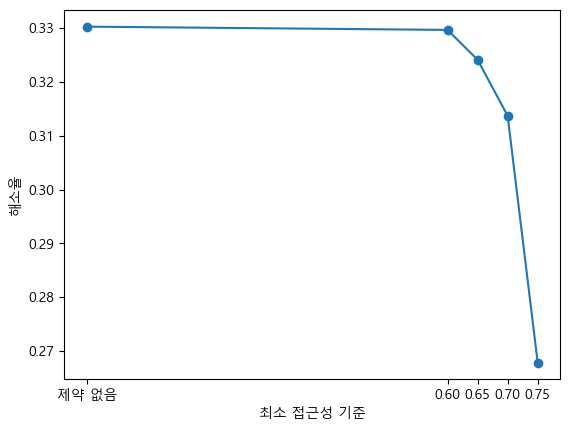

In [79]:
trade.plot(marker='o')
plt.xticks(flo, ['제약 없음', '0.60', '0.65', '0.70', '0.75'])
plt.xlabel('최소 접근성 기준')
plt.ylabel('해소율')
plt.show()

In [80]:
T = 0.70

# 효율 vs 평준화

In [81]:
def rate(col, asc):
    d = route.sort_values(col, ascending=asc)
    keep = d.index[d['미저상대수'].cumsum() <= bud]
    return route['미저상대수'].where(route.index.isin(keep), 0).to_numpy()

In [82]:
x = {'효율형': max_effect(bud), '평준형': max_effect(bud, T), '보유율 낮은 순': rate('저상율', True), '이용객 많은 순': rate('승하차', False)}

In [83]:
def summary(v):
    after = acc + A @ v
    return pd.Series({'투입대수': v.sum(), '해소인원': gain @ v, '해소율': gain @ v / (gain @ ub),
                      '최저접근성': after.min(), '기준미달 동': (after < np.minimum(T, acc_max) - 1e-6).sum()})

comp = pd.DataFrame({k: summary(v) for k, v in x.items()})
comp.round(3)

,효율형,평준형,보유율 낮은 순,이용객 많은 순
투입대수,300.000,300.000,297.000,298.000
해소인원,126167.554,119840.912,79336.445,77341.602
해소율,0.330,0.314,0.208,0.202
최저접근성,0.538,0.700,0.539,0.287
기준미달 동,24.000,0.000,26.000,43.000


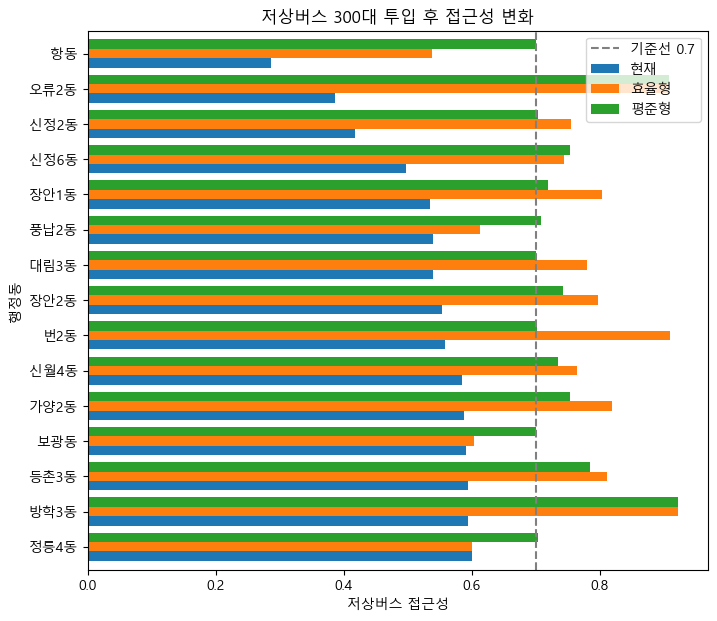

In [84]:
res = dong[['행정동']].assign(현재=acc, 효율형=acc + A @ x['효율형'], 평준형=acc + A @ x['평준형'])
worst = res.nsmallest(15, '현재').set_index('행정동').iloc[::-1]
worst.plot.barh(figsize=(8, 7), width=0.8)
plt.axvline(T, ls='--', c='gray', label=f'기준선 {T}')
plt.xlabel('저상버스 접근성')
plt.title(f'저상버스 {bud}대 투입 후 접근성 변화')
plt.legend()
plt.show()

In [85]:
plan = route[['노선', '저상율', '미저상대수', '대당효과']]
plan.head()

,노선,저상율,미저상대수,대당효과
0,040,0.600000,6,282.767170
1,0411,0.954545,1,177.054161
2,101,0.612903,12,292.397882
3,1020,0.333333,10,106.582624
4,107,0.960000,1,164.391962


# 탄소배출
$$
\text{CO}_2\text{감축량(톤)} = \frac{N_{\text{해소}} \times T_{\text{일통행}} \times r_{\text{전환}} \times 365 \times D_{\text{평균거리}} \times \Delta E}{10^6}
$$

In [116]:
#파라미터 (출처: 서울시 주요교통통계, 서울시 도시교통실 교통이용통계보고서, 환경부 온실가스 관리제도 이행실적, IEEE-VPPC 측정자료, 한국교통연구원 가구통행실태조사)
# 파라미터 값의 경우 상황에 맞게 설정 후 사용
car_taxi = 0.306 #(승용차+택시)
avg_km = 8.11
emis_car = 210.0
emis_bus = 27.6
emis_diff = emis_car - emis_bus

In [117]:
shift_r = {'1%': 0.01, '3%': 0.03, '5%': 0.05}

In [118]:
def co2(resolved, rate):
    shifted_trips = resolved * rate * 365
    return (shifted_trips * avg_km * emis_diff) / 1_000_000.0

# CO2 감축량

In [119]:
co2_tab = pd.DataFrame([(k, s, comp.loc['투입대수', k], co2(comp.loc['해소인원', k], rate))
                        for k in comp for s, rate in shift_r.items()],
                       columns=['전략', '시나리오', '투입대수', 'co2_ton'])
co2_tab['co2_per_bus'] = co2_tab['co2_ton'] / co2_tab['투입대수']
co2_tab.pivot(index='전략', columns='시나리오', values='co2_ton').reindex(index=comp.columns, columns=shift_r.keys()).round(1)

시나리오,1%,3%,5%
효율형,681.2,2043.7,3406.1
평준형,647.1,1941.2,3235.3
보유율 낮은 순,428.4,1285.1,2141.8
이용객 많은 순,417.6,1252.8,2088.0


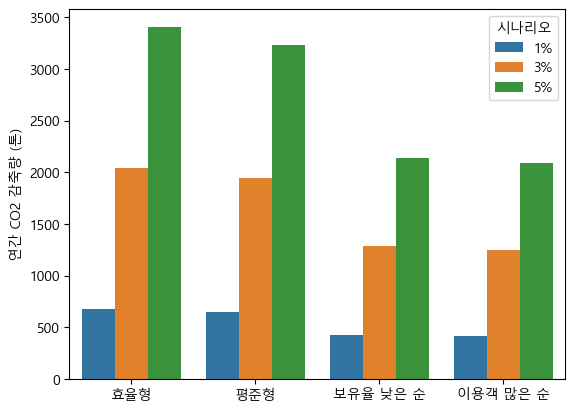

In [120]:
sns.barplot(data=co2_tab, x='전략', y='co2_ton', hue='시나리오', order=comp.columns, hue_order=shift_r.keys())
plt.ylabel('연간 CO2 감축량 (톤)')
plt.xlabel('')
plt.show()

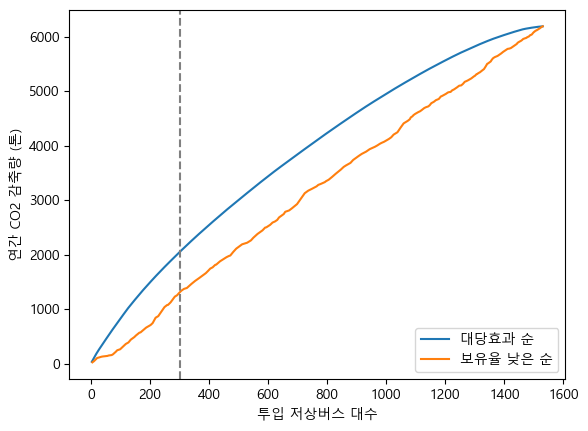

In [121]:
for name, col, asc in [('대당효과 순', '대당효과', False), ('보유율 낮은 순', '저상율', True)]:
    d = route.sort_values(col, ascending=asc)
    plt.plot(d['미저상대수'].cumsum(), co2(d['해소효과'].cumsum(), 0.03), label=name)
plt.axvline(bud, ls='--', c='gray')
plt.xlabel('투입 저상버스 대수')
plt.ylabel('연간 CO2 감축량 (톤)')
plt.legend()
plt.show()

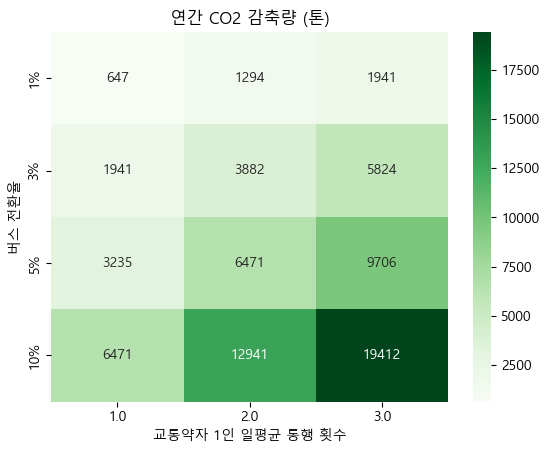

In [122]:
rates = [0.01, 0.03, 0.05, 0.10]
trips = [1.0, 2.0, 3.0]
grid = pd.DataFrame([[co2(comp.loc['해소인원', '평준형'], r) * t for t in trips] for r in rates], index=[f'{r:.0%}' for r in rates], columns=trips)
sns.heatmap(grid, annot=True, fmt='.0f', cmap='Greens')
plt.xlabel('교통약자 1인 일평균 통행 횟수')
plt.ylabel('버스 전환율')
plt.title('연간 CO2 감축량 (톤)')
plt.show()

# 최종 요약

In [123]:
final = comp.loc[['투입대수', '해소인원', '해소율', '최저접근성', '기준미달 동']].copy()
final.loc['CO2 감축'] = co2(final.loc['해소인원'], 0.03)
final.round(2)

,효율형,평준형,보유율 낮은 순,이용객 많은 순
투입대수,300.00,300.00,297.00,298.00
해소인원,126167.55,119840.91,79336.45,77341.60
해소율,0.33,0.31,0.21,0.20
최저접근성,0.54,0.70,0.54,0.29
기준미달 동,24.00,0.00,26.00,43.00
CO2 감축,2043.65,1941.18,1285.09,1252.77


In [124]:
plan = route[['노선', '저상율', '미저상대수', '대당효과']].assign(효율형=x['효율형'], 형평형=x['평준형'])
plan['단계'] = np.select([(plan['효율형'] > 0) & (plan['형평형'] > 0), plan['형평형'] > 0], ['1단계', '2단계'], '')

In [125]:
benefit = route_dong.assign(효과=route_dong['교통약자'] * route_dong['대당증가'])
benefit = benefit.sort_values('효과', ascending=False).groupby('노선').head(2).groupby('노선')['행정동'].agg(', '.join)

In [126]:
final_plan = plan[plan['형평형'] > 0].sort_values(['단계', '대당효과'], ascending=[True, False])
final_plan['주요 수혜 동'] = final_plan['노선'].map(benefit)
final_plan

,노선,저상율,미저상대수,대당효과,효율형,형평형,단계,주요 수혜 동
77,3321,0.700000,3,650.947405,3.0,3.0,1단계,"천호1동, 천호2동"
17,1167,0.230769,10,608.648097,10.0,10.0,1단계,"방학2동, 중계본동"
85,3413,0.807692,5,575.149278,5.0,5.0,1단계,"천호1동, 길동"
14,1135,0.800000,2,558.897541,2.0,2.0,1단계,"중계2.3동, 공릉1동"
75,3318,0.800000,4,505.415389,4.0,4.0,1단계,"암사1동, 강일동"
69,3214,0.545455,5,504.474039,5.0,5.0,1단계,"구의3동, 오금동"
184,6648,0.928571,1,503.270519,1.0,1.0,1단계,"방화1동, 신월1동"
81,340,0.685714,11,495.308489,11.0,11.0,1단계,"암사1동, 천호2동"
53,2312,0.578947,8,492.249428,8.0,8.0,1단계,"둔촌2동, 천호1동"
163,652,0.250000,21,486.713011,21.0,21.0,1단계,"화곡1동, 등촌3동"


In [127]:
final_plan.groupby('단계').agg(노선수=('노선', 'count'), 투입대수=('형평형', 'sum'))

,노선수,투입대수
단계,,
1단계,36,228.0
2단계,21,72.0


In [128]:
final_plan[final_plan['저상율'].eq(0)]

,노선,저상율,미저상대수,대당효과,효율형,형평형,단계,주요 수혜 동
135,5611,0.0,5,351.457534,5.0,2.0,1단계,"대림3동, 구로5동"
48,2224,0.0,11,332.829686,11.0,2.0,1단계,"성수1가1동, 자양3동"
10,1113,0.0,5,265.992457,0.0,4.0,2단계,"월곡1동, 정릉4동"
11,1116,0.0,5,242.671042,0.0,5.0,2단계,"삼각산동, 송천동"


In [129]:
route[route['저상율'].eq(0)][['노선', '미저상대수', '해소효과', '대당효과']].sort_values('해소효과', ascending=False)

,노선,미저상대수,해소효과,대당효과
48,2224,11,3661.126542,332.829686
170,6617,10,2983.253281,298.325328
135,5611,5,1757.287670,351.457534
104,422,15,1497.707762,99.847184
10,1113,5,1329.962287,265.992457
11,1116,5,1213.355211,242.671042
219,7739,8,882.328299,110.291037
214,7719,4,689.791008,172.447752
232,N30,4,472.498355,118.124589
221,8221,6,309.955702,51.659284
